In [3]:
!pip install -q rasterio matplotlib-scalebar

In [4]:
import os, json, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

CRS_WORK = "EPSG:32637"   # UTM zone 37N, in metres
CELL = 500                # working grid resolution (m)
SEED = 42                 # fixes the random weights in Section 7

print("geopandas", gpd.__version__, "| rasterio", rasterio.__version__, "| numpy", np.__version__)

geopandas 1.2.0 | rasterio 1.5.2 | numpy 2.4.6


In [6]:
from google.colab import drive
drive.mount("/content/drive")

PROJ = "/content/drive/MyDrive/eritrea-solar-suitability"
DATA = f"{PROJ}/data"
OUT  = f"{PROJ}/outputs"
for d in (DATA, OUT):
    os.makedirs(d, exist_ok=True)
print("Project folder:", PROJ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/eritrea-solar-suitability


Source: OpenStreetMap, Wambacher | Year: 2017
Original CRS: EPSG:4326
Bounds (lon/lat): [36.433 12.355 43.137 18.02 ]
Area (km²): 120384


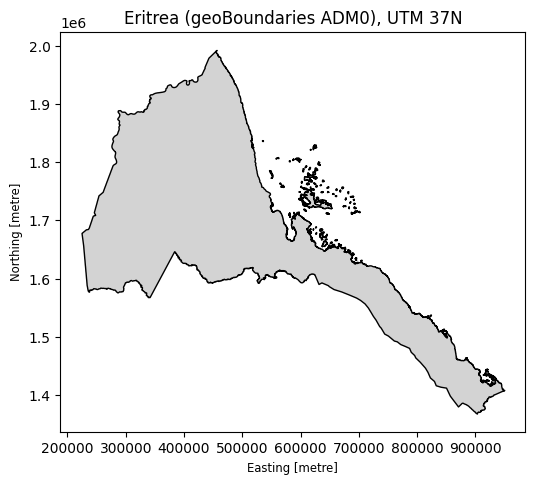

In [8]:
api = "https://www.geoboundaries.org/api/current/gbOpen/ERI/ADM0/"
meta = requests.get(api, timeout=60).json()
print("Source:", meta.get("boundarySource"), "| Year:", meta.get("boundaryYearRepresented"))

bnd_path = f"{DATA}/eri_adm0.geojson"
r = requests.get(meta["gjDownloadURL"], timeout=180)
r.raise_for_status()
with open(bnd_path, "wb") as f:
    f.write(r.content)

eri = gpd.read_file(bnd_path)
eri_utm = eri.to_crs(CRS_WORK)

print("Original CRS:", eri.crs)
print("Bounds (lon/lat):", np.round(eri.total_bounds, 3))
print("Area (km²):", round(eri_utm.area.sum() / 1e6))

ax = eri_utm.plot(edgecolor="black", facecolor="lightgrey", figsize=(6, 6))
ax.set_title("Eritrea (geoBoundaries ADM0), UTM 37N")
plt.show()

Zip found: ['/content/drive/MyDrive/eritrea-solar-suitability/data/Eritrea_GISdata_LTAym_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF.zip']
CRS: EPSG:4326 | pixel size: (0.0025, 0.0025) | shape: (2800, 3200)
GHI kWh/m²/day  min: 3.66  mean: 6.02  max: 6.53


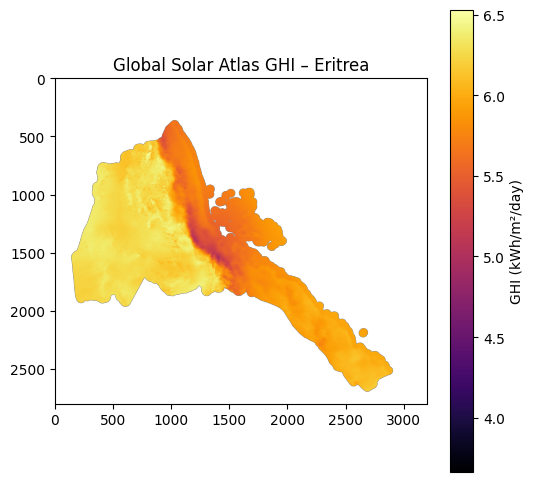

In [10]:
import zipfile, glob

zips = glob.glob(f"{DATA}/*.zip")
print("Zip found:", zips)

with zipfile.ZipFile(zips[0]) as z:
    ghi_name = [n for n in z.namelist() if n.lower().endswith("ghi.tif")][0]
    z.extract(ghi_name, f"{DATA}/gsa")
ghi_path = f"{DATA}/gsa/{ghi_name}"

with rasterio.open(ghi_path) as src:
    print("CRS:", src.crs, "| pixel size:", src.res, "| shape:", src.shape)
    ghi = src.read(1, masked=True)

print("GHI kWh/m²/day  min:", round(float(ghi.min()), 2),
      " mean:", round(float(ghi.mean()), 2),
      " max:", round(float(ghi.max()), 2))

plt.figure(figsize=(6, 6))
plt.imshow(ghi, cmap="inferno")
plt.colorbar(label="GHI (kWh/m²/day)")
plt.title("Global Solar Atlas GHI – Eritrea")
plt.show()

Grid (rows, cols): (1248, 1451)
Cells inside Eritrea: 481526 → 120382 km²
Cells inside Eritrea with no GHI value: 0
GHI 500 m  min: 4.74  mean: 6.07  max: 6.51


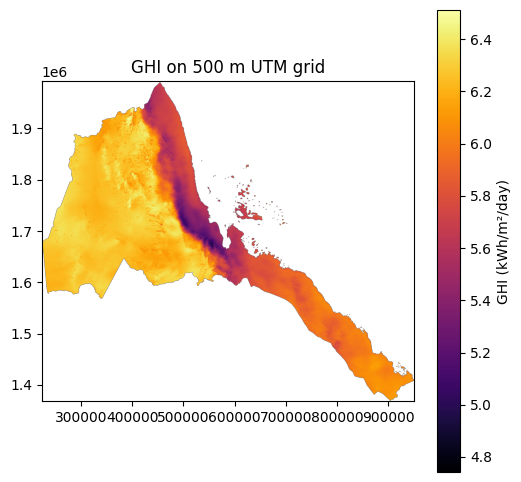

In [11]:
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from rasterio.features import rasterize
import glob

# Boundary and grid
eri_utm = gpd.read_file(f"{DATA}/eri_adm0.geojson").to_crs(CRS_WORK)
xmin, ymin, xmax, ymax = eri_utm.total_bounds
xmin, ymin = np.floor(xmin / CELL) * CELL, np.floor(ymin / CELL) * CELL
xmax, ymax = np.ceil(xmax / CELL) * CELL,  np.ceil(ymax / CELL) * CELL
W, H = int((xmax - xmin) / CELL), int((ymax - ymin) / CELL)
TRANSFORM = from_origin(xmin, ymax, CELL, CELL)
EXTENT = (xmin, xmax, ymin, ymax)   # for plotting

MASK = rasterize([(g, 1) for g in eri_utm.geometry], out_shape=(H, W),
                 transform=TRANSFORM, fill=0, dtype="uint8").astype(bool)

# Helpers used in every later section
def to_grid(src_path, resampling=Resampling.average):
    out = np.full((H, W), np.nan, dtype="float32")
    with rasterio.open(src_path) as src:
        reproject(rasterio.band(src, 1), out,
                  dst_transform=TRANSFORM, dst_crs=CRS_WORK,
                  dst_nodata=np.nan, resampling=resampling)
    out[~MASK] = np.nan
    return out

def save_tif(arr, path):
    with rasterio.open(path, "w", driver="GTiff", height=H, width=W, count=1,
                       dtype="float32", crs=CRS_WORK, transform=TRANSFORM,
                       nodata=np.nan, compress="deflate") as dst:
        dst.write(arr.astype("float32"), 1)

# GHI on the grid
ghi_path = glob.glob(f"{DATA}/gsa/**/GHI.tif", recursive=True)[0]
ghi500 = to_grid(ghi_path)
save_tif(ghi500, f"{DATA}/ghi_500m.tif")

print("Grid (rows, cols):", (H, W))
print("Cells inside Eritrea:", int(MASK.sum()), "→", round(MASK.sum() * 0.25), "km²")
print("Cells inside Eritrea with no GHI value:", int(np.isnan(ghi500[MASK]).sum()))
print("GHI 500 m  min:", round(float(np.nanmin(ghi500)), 2),
      " mean:", round(float(np.nanmean(ghi500)), 2),
      " max:", round(float(np.nanmax(ghi500)), 2))

plt.figure(figsize=(6, 6))
plt.imshow(ghi500, cmap="inferno", extent=EXTENT)
plt.colorbar(label="GHI (kWh/m²/day)")
plt.title("GHI on 500 m UTM grid")
plt.show()

DEM tiles downloaded: 47
Elevation m   min: -124  max: 2946
Slope °  mean: 5.49  max: 52.1
Share of Eritrea with slope > 10°: 5.6 %


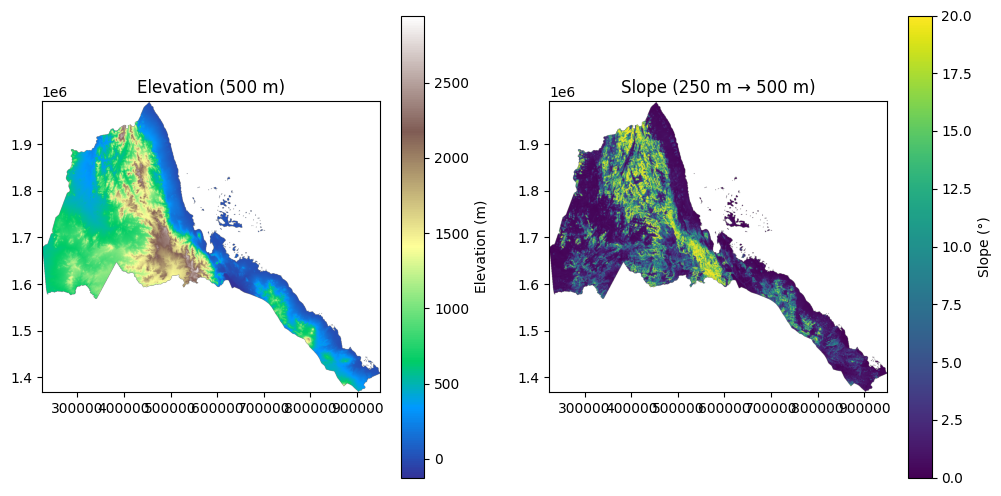

In [12]:
from rasterio.merge import merge

# 1) Download 1°×1° DEM tiles (sea-only tiles don't exist → skipped)
TILE_DIR = "/content/dem_tiles"          # temporary, fast local disk
os.makedirs(TILE_DIR, exist_ok=True)
base = "https://copernicus-dem-90m.s3.amazonaws.com"
paths = []
for lat in range(12, 18):
    for lon in range(36, 44):
        name = f"Copernicus_DSM_COG_30_N{lat:02d}_00_E{lon:03d}_00_DEM"
        p = f"{TILE_DIR}/{name}.tif"
        if not os.path.exists(p):
            r = requests.get(f"{base}/{name}/{name}.tif", timeout=300)
            if r.status_code != 200:
                continue
            with open(p, "wb") as f:
                f.write(r.content)
        paths.append(p)
print("DEM tiles downloaded:", len(paths))

# 2) Mosaic and reproject to a 250 m UTM grid (same origin as the 500 m grid)
dem, dem_tr = merge(paths, nodata=-9999)
with rasterio.open(paths[0]) as s:
    dem_crs = s.crs
TR250 = from_origin(xmin, ymax, 250, 250)
dem250 = np.full((H * 2, W * 2), np.nan, dtype="float32")
reproject(dem[0].astype("float32"), dem250,
          src_transform=dem_tr, src_crs=dem_crs, src_nodata=-9999,
          dst_transform=TR250, dst_crs=CRS_WORK, dst_nodata=np.nan,
          resampling=Resampling.average)
del dem

# 3) Slope at 250 m (degrees); missing areas are open sea → set to 0 m
z = np.nan_to_num(dem250, nan=0.0)
dzdy, dzdx = np.gradient(z, 250)
slope250 = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

# 4) Average 2×2 blocks → 500 m, clip to Eritrea, save
slope500 = slope250.reshape(H, 2, W, 2).mean(axis=(1, 3)).astype("float32")
elev500  = z.reshape(H, 2, W, 2).mean(axis=(1, 3)).astype("float32")
slope500[~MASK] = np.nan
elev500[~MASK] = np.nan
save_tif(slope500, f"{DATA}/slope_500m.tif")
save_tif(elev500,  f"{DATA}/elev_500m.tif")

print("Elevation m   min:", round(float(np.nanmin(elev500))),
      " max:", round(float(np.nanmax(elev500))))
print("Slope °  mean:", round(float(np.nanmean(slope500)), 2),
      " max:", round(float(np.nanmax(slope500)), 1))
print("Share of Eritrea with slope > 10°:",
      round(100 * float(np.nanmean(slope500 > 10)), 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
im0 = ax[0].imshow(elev500, cmap="terrain", extent=EXTENT)
plt.colorbar(im0, ax=ax[0], label="Elevation (m)")
ax[0].set_title("Elevation (500 m)")
im1 = ax[1].imshow(slope500, cmap="viridis", vmax=20, extent=EXTENT)
plt.colorbar(im1, ax=ax[1], label="Slope (°)")
ax[1].set_title("Slope (250 m → 500 m)")
plt.show()

In [14]:
import matplotlib.patches as mpatches
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"   # faster cloud reads

WC_BASE = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map"
lc500 = np.zeros((H, W), dtype="uint8")       # 0 = no data

for lat in (12, 15, 18):
    for lon in (36, 39, 42):
        tile = f"N{lat:02d}E{lon:03d}"
        url = f"{WC_BASE}/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
        try:
            with rasterio.open(url, overview_level=3) as src:   # ~160 m version
                arr = src.read(1)
                tmp = np.zeros((H, W), dtype="uint8")
                reproject(arr, tmp, src_transform=src.transform, src_crs=src.crs,
                          src_nodata=0, dst_transform=TRANSFORM, dst_crs=CRS_WORK,
                          dst_nodata=0, resampling=Resampling.mode)
            lc500 = np.where(tmp > 0, tmp, lc500)
            print("read", tile, "| overview pixel size (deg):", round(src.res[0], 5))
        except rasterio.errors.RasterioIOError:
            print("no tile", tile)

lc500[~MASK] = 0
lc_f = lc500.astype("float32"); lc_f[lc500 == 0] = np.nan
save_tif(lc_f, f"{DATA}/landcover_500m.tif")

# Class shares inside Eritrea
WC = {10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"),
      30: ("Grassland", "#ffff4c"), 40: ("Cropland", "#f096ff"),
      50: ("Built-up", "#fa0000"), 60: ("Bare/sparse", "#b4b4b4"),
      70: ("Snow/ice", "#f0f0f0"), 80: ("Water", "#0064c8"),
      90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"),
      100: ("Moss/lichen", "#fae6a0")}
vals, counts = np.unique(lc500[MASK], return_counts=True)
print("\nLand cover inside Eritrea:")
for v, c in zip(vals, counts):
    print(f"  {v:>3} {WC.get(v, ('No data',))[0]:<20} {100 * c / MASK.sum():5.1f} %")

# Map
rgb = np.ones((H, W, 3))
for v, (name, col) in WC.items():
    rgb[lc500 == v] = mpatches.Patch(color=col).get_facecolor()[:3]
plt.figure(figsize=(7, 7))
plt.imshow(rgb, extent=EXTENT)
plt.legend(handles=[mpatches

_IncompleteInputError: incomplete input (3222620218.py, line 45)

In [16]:
# Map
rgb = np.ones((H, W, 3))
for v, (name, col) in WC.items():
    rgb[lc500 == v] = mpatches.Patch(color=col).get_facecolor()[:3]

handles = []
for v in vals:
    if v in WC:
        handles.append(mpatches.Patch(color=WC[v][1], label=WC[v][0]))

plt.figure(figsize=(7, 7))
plt.imshow(rgb, extent=EXTENT)
plt.legend(handles=handles, loc="upper right", fontsize=8)
plt.title("ESA WorldCover 2021 (mode, 500 m)")
plt.show()

NameError: name 'WC' is not defined

read N12E036 | pixel size (deg): 0.00133
read N12E039 | pixel size (deg): 0.00133
read N12E042 | pixel size (deg): 0.00133
read N15E036 | pixel size (deg): 0.00133
read N15E039 | pixel size (deg): 0.00133
read N15E042 | pixel size (deg): 0.00133
read N18E036 | pixel size (deg): 0.00133
read N18E039 | pixel size (deg): 0.00133
read N18E042 | pixel size (deg): 0.00133

Land cover inside Eritrea:
   10 Tree cover             0.3 %
   20 Shrubland             12.4 %
   30 Grassland             28.9 %
   40 Cropland               4.4 %
   50 Built-up               0.1 %
   60 Bare/sparse           53.8 %
   80 Water                  0.1 %
   90 Herbaceous wetland     0.0 %
   95 Mangroves              0.0 %


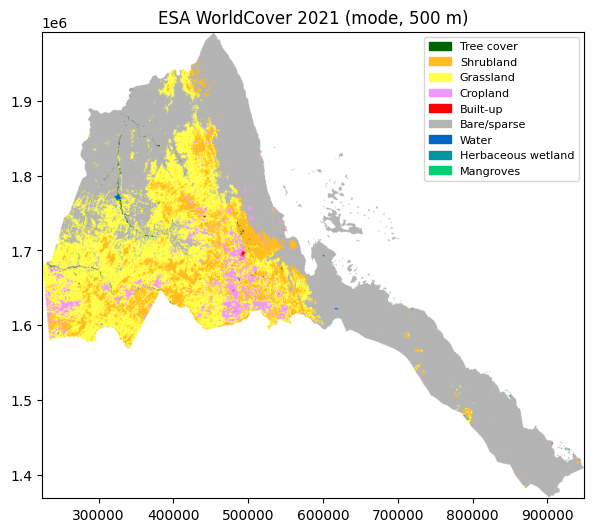

In [17]:
import matplotlib.patches as mpatches
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

WC_BASE = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map"
lc500 = np.zeros((H, W), dtype="uint8")   # 0 = no data

for lat in (12, 15, 18):
    for lon in (36, 39, 42):
        tile = f"N{lat:02d}E{lon:03d}"
        url = f"{WC_BASE}/ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
        try:
            with rasterio.open(url, overview_level=3) as src:
                arr = src.read(1)
                tmp = np.zeros((H, W), dtype="uint8")
                reproject(arr, tmp,
                          src_transform=src.transform,
                          src_crs=src.crs, src_nodata=0,
                          dst_transform=TRANSFORM,
                          dst_crs=CRS_WORK, dst_nodata=0,
                          resampling=Resampling.mode)
                res = round(src.res[0], 5)
            lc500 = np.where(tmp > 0, tmp, lc500)
            print("read", tile, "| pixel size (deg):", res)
        except rasterio.errors.RasterioIOError:
            print("no tile", tile)

lc500[~MASK] = 0
lc_f = lc500.astype("float32")
lc_f[lc500 == 0] = np.nan
save_tif(lc_f, f"{DATA}/landcover_500m.tif")

WC = {
    10: ("Tree cover", "#006400"),
    20: ("Shrubland", "#ffbb22"),
    30: ("Grassland", "#ffff4c"),
    40: ("Cropland", "#f096ff"),
    50: ("Built-up", "#fa0000"),
    60: ("Bare/sparse", "#b4b4b4"),
    70: ("Snow/ice", "#f0f0f0"),
    80: ("Water", "#0064c8"),
    90: ("Herbaceous wetland", "#0096a0"),
    95: ("Mangroves", "#00cf75"),
    100: ("Moss/lichen", "#fae6a0"),
}

vals, counts = np.unique(lc500[MASK], return_counts=True)
print("\nLand cover inside Eritrea:")
for v, c in zip(vals, counts):
    name = WC[v][0] if v in WC else "No data"
    share = 100 * c / MASK.sum()
    print(f"  {v:>3} {name:<20} {share:5.1f} %")

# Map
rgb = np.ones((H, W, 3))
for v, (name, col) in WC.items():
    rgb[lc500 == v] = mpatches.Patch(color=col).get_facecolor()[:3]

handles = []
for v in vals:
    if v in WC:
        handles.append(mpatches.Patch(color=WC[v][1], label=WC[v][0]))

plt.figure(figsize=(7, 7))
plt.imshow(rgb, extent=EXTENT)
plt.legend(handles=handles, loc="upper right", fontsize=8)
plt.title("ESA WorldCover 2021 (mode, 500 m)")
plt.show()

OSM file size (MB): 32.2
Power lines: 14 ways, 162 km
Main roads: 1644 ways, 3202 km
Road types: {'trunk': 669, 'primary': 454, 'secondary': 454, 'trunk_link': 34, 'secondary_link': 17, 'primary_link': 16}
Voltages: {'': 9, '66000': 3, '132000': 2}
Distance to power line (km)  median: 163.3  max: 508.6
Distance to main road (km)   median: 16.4  max: 150.1
Share within 50 km of a power line: 3.5 %
Share within 20 km of a main road: 15.0 %


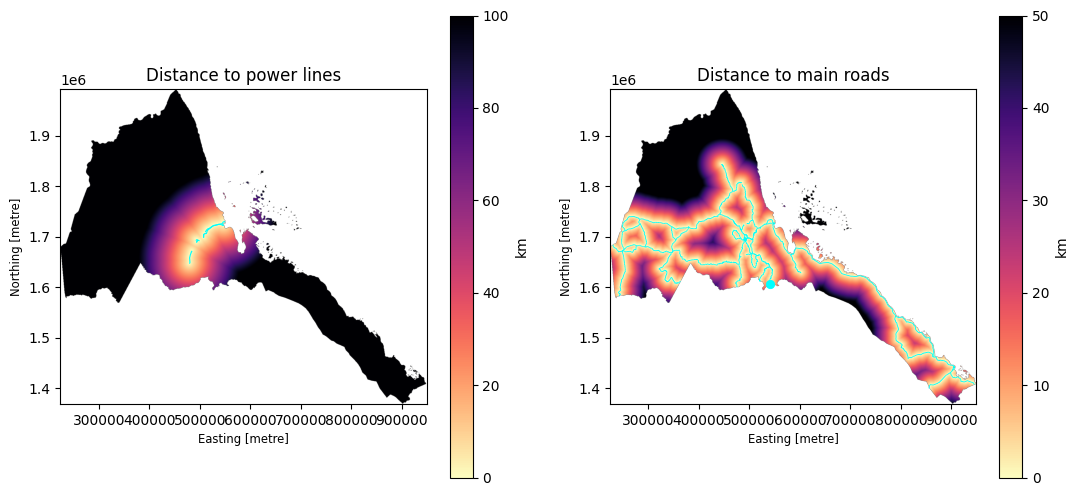

In [20]:
!pip install -q osmium
import osmium
from shapely import wkb as shp_wkb
from scipy.ndimage import distance_transform_edt

# 1) Download the OSM extract for Eritrea (Geofabrik)
pbf = f"{DATA}/eritrea-latest.osm.pbf"
if not os.path.exists(pbf):
    r = requests.get("https://download.geofabrik.de/africa/eritrea-latest.osm.pbf",
                     headers={"User-Agent": "eritrea-solar-suitability student project"},
                     timeout=600)
    r.raise_for_status()
    with open(pbf, "wb") as f:
        f.write(r.content)
print("OSM file size (MB):", round(os.path.getsize(pbf) / 1e6, 1))

# 2) Pull out power lines and main roads
MAIN = {"trunk", "primary", "secondary",
        "trunk_link", "primary_link", "secondary_link"}

class LineGrabber(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.fab = osmium.geom.WKBFactory()
        self.rows = []
    def way(self, w):
        if w.tags.get("power") == "line":
            layer, kind = "power", w.tags.get("voltage", "")
        elif w.tags.get("highway") in MAIN:
            layer, kind = "road", w.tags.get("highway")
        else:
            return
        try:
            g = shp_wkb.loads(self.fab.create_linestring(w), hex=True)
        except Exception:
            return
        self.rows.append((layer, w.id, kind, g))

h = LineGrabber()
h.apply_file(pbf, locations=True)
osm = gpd.GeoDataFrame(h.rows, columns=["layer", "osm_id", "kind", "geometry"],
                       crs="EPSG:4326").to_crs(CRS_WORK)
osm = gpd.clip(osm, eri_utm)            # keep only lines inside Eritrea

power = osm[osm.layer == "power"]
roads = osm[osm.layer == "road"]
power.to_file(f"{DATA}/osm_power_lines.geojson", driver="GeoJSON")
roads.to_file(f"{DATA}/osm_main_roads.geojson", driver="GeoJSON")
print("Power lines:", len(power), "ways,", round(power.length.sum() / 1000), "km")
print("Main roads:", len(roads), "ways,", round(roads.length.sum() / 1000), "km")
print("Road types:", roads["kind"].value_counts().to_dict())
print("Voltages:", power["kind"].value_counts().to_dict())

# 3) Distance rasters (km)
def dist_km(gdf):
    lines = rasterize([(g, 1) for g in gdf.geometry], out_shape=(H, W),
                      transform=TRANSFORM, fill=0, all_touched=True,
                      dtype="uint8")
    d = distance_transform_edt(lines == 0) * CELL / 1000
    d = d.astype("float32")
    d[~MASK] = np.nan
    return d

d_power = dist_km(power)
d_roads = dist_km(roads)
save_tif(d_power, f"{DATA}/dist_power_km.tif")
save_tif(d_roads, f"{DATA}/dist_roads_km.tif")

print("Distance to power line (km)  median:", round(float(np.nanmedian(d_power)), 1),
      " max:", round(float(np.nanmax(d_power)), 1))
print("Distance to main road (km)   median:", round(float(np.nanmedian(d_roads)), 1),
      " max:", round(float(np.nanmax(d_roads)), 1))
print("Share within 50 km of a power line:",
      round(100 * float(np.nanmean(d_power <= 50)), 1), "%")
print("Share within 20 km of a main road:",
      round(100 * float(np.nanmean(d_roads <= 20)), 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
im0 = ax[0].imshow(d_power, cmap="magma_r", vmax=100, extent=EXTENT)
power.plot(ax=ax[0], color="cyan", linewidth=0.8)
plt.colorbar(im0, ax=ax[0], label="km")
ax[0].set_title("Distance to power lines")
im1 = ax[1].imshow(d_roads, cmap="magma_r", vmax=50, extent=EXTENT)
roads.plot(ax=ax[1], color="cyan", linewidth=0.6)
plt.colorbar(im1, ax=ax[1], label="km")
ax[1].set_title("Distance to main roads")
plt.show()

Gridfinder file (MB): 725
CRS: EPSG:4326 | columns: ['source', 'geometry']
Gridfinder lines in Eritrea: 170 | 1714 km
By source: {'gridfinder': 165, 'openstreetmap': 5}
Distance to power line (km)  median: 27.8  max: 279.0
Share within 50 km of a line: Gridfinder 18.0 % | OSM only 3.5 %


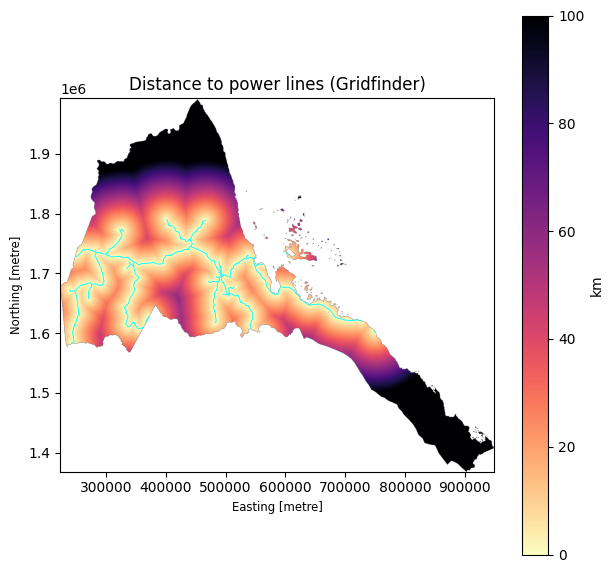

In [21]:
# Keep the OSM-only version for a later comparison
d_power_osm = d_power.copy()
save_tif(d_power_osm, f"{DATA}/dist_power_osm_km.tif")

# Download Gridfinder (global, temporary local copy)
GF = "/content/grid.gpkg"
if not os.path.exists(GF):
    url = "https://zenodo.org/records/3628142/files/grid.gpkg?download=1"
    with requests.get(url, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(GF, "wb") as f:
            for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
                f.write(chunk)
print("Gridfinder file (MB):", round(os.path.getsize(GF) / 1e6))

# Read only the Eritrea area
lon0, lat0, lon1, lat1 = gpd.read_file(f"{DATA}/eri_adm0.geojson").total_bounds
grid = gpd.read_file(GF, bbox=(lon0 - 0.2, lat0 - 0.2, lon1 + 0.2, lat1 + 0.2))
print("CRS:", grid.crs, "| columns:", grid.columns.tolist())
grid = gpd.clip(grid.to_crs(CRS_WORK), eri_utm)
grid.to_file(f"{DATA}/gridfinder_eritrea.geojson", driver="GeoJSON")
print("Gridfinder lines in Eritrea:", len(grid), "|",
      round(grid.length.sum() / 1000), "km")
if "source" in grid.columns:
    print("By source:", grid["source"].value_counts().to_dict())

# New distance layer
d_power = dist_km(grid)
save_tif(d_power, f"{DATA}/dist_power_km.tif")
print("Distance to power line (km)  median:", round(float(np.nanmedian(d_power)), 1),
      " max:", round(float(np.nanmax(d_power)), 1))
print("Share within 50 km of a line: Gridfinder",
      round(100 * float(np.nanmean(d_power <= 50)), 1), "% | OSM only",
      round(100 * float(np.nanmean(d_power_osm <= 50)), 1), "%")

plt.figure(figsize=(7, 7))
plt.imshow(d_power, cmap="magma_r", vmax=100, extent=EXTENT)
plt.colorbar(label="km")
grid.plot(ax=plt.gca(), color="cyan", linewidth=0.6)
plt.title("Distance to power lines (Gridfinder)")
plt.show()

Excluded by slope > 10°:      20.9 %
Excluded by land cover:       0.4 %
Usable land: 378734 cells = 94684 km² (78.7 % of Eritrea)
Mean factor scores on usable land: {'GHI': 0.71, 'Slope': 0.74, 'Land cover': 0.92, 'Power lines': 0.43, 'Roads': 0.36}
Suitability  min: 0.184  median: 0.596  max: 0.961
Top-10 % threshold: 0.837 | top-10 % area: 9468 km²


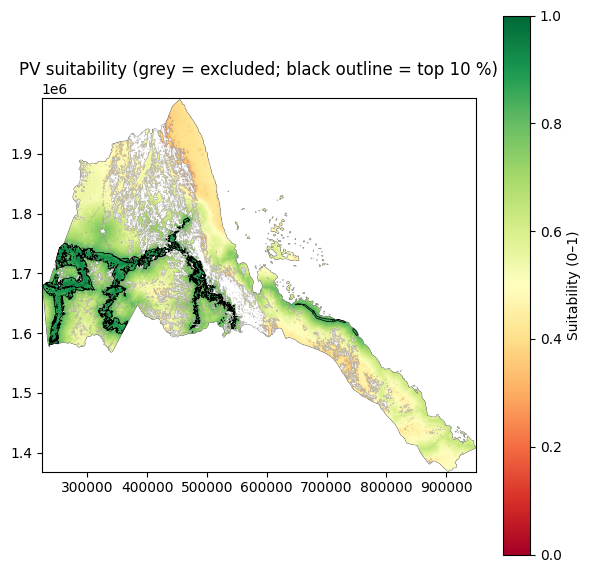

In [22]:
def load(name):
    with rasterio.open(f"{DATA}/{name}") as s:
        return s.read(1)

ghi   = load("ghi_500m.tif")
slope = load("slope_500m.tif")
lc    = np.nan_to_num(load("landcover_500m.tif"), nan=0).astype(int)
dpow  = load("dist_power_km.tif")
droad = load("dist_roads_km.tif")

# Exclusions
LC_SCORE = {60: 1.0, 30: 0.9, 20: 0.8, 40: 0.4}    # bare, grass, shrub, crop
ex_slope = MASK & (slope > 10)
ex_lc    = MASK & ~np.isin(lc, list(LC_SCORE))      # tree, built-up, water, wetland, mangrove
valid = (MASK & ~ex_slope & ~ex_lc
         & np.isfinite(ghi) & np.isfinite(dpow) & np.isfinite(droad))

# Scores 0-1 (linear)
s_ghi   = np.clip((ghi - 5.0) / (6.5 - 5.0), 0, 1)
s_slope = np.clip((10 - slope) / 10, 0, 1)
s_lc    = np.zeros_like(ghi)
for k, v in LC_SCORE.items():
    s_lc[lc == k] = v
s_pow   = np.clip(1 - dpow / 50, 0, 1)
s_road  = np.clip(1 - droad / 20, 0, 1)

FACTORS = ["GHI", "Slope", "Land cover", "Power lines", "Roads"]
W0 = np.array([0.35, 0.15, 0.10, 0.25, 0.15])
S = np.stack([s_ghi[valid], s_slope[valid], s_lc[valid],
              s_pow[valid], s_road[valid]])          # shape (5, n_valid)

score_v = W0 @ S
suit = np.full((H, W), np.nan, dtype="float32")
suit[valid] = score_v
save_tif(suit, f"{OUT}/suitability_500m.tif")

top_thr = np.percentile(score_v, 90)
n_all = MASK.sum()
print("Excluded by slope > 10°:     ", round(100 * ex_slope.sum() / n_all, 1), "%")
print("Excluded by land cover:      ", round(100 * ex_lc.sum() / n_all, 1), "%")
print("Usable land:", valid.sum(), "cells =", round(valid.sum() * 0.25), "km²",
      f"({round(100 * valid.sum() / n_all, 1)} % of Eritrea)")
print("Mean factor scores on usable land:",
      {f: round(float(m), 2) for f, m in zip(FACTORS, S.mean(axis=1))})
print("Suitability  min:", round(float(score_v.min()), 3),
      " median:", round(float(np.median(score_v)), 3),
      " max:", round(float(score_v.max()), 3))
print("Top-10 % threshold:", round(float(top_thr), 3),
      "| top-10 % area:", round((score_v >= top_thr).sum() * 0.25), "km²")

plt.figure(figsize=(7, 7))
plt.imshow(np.where(MASK, 0, np.nan), cmap="Greys", vmin=0, vmax=3, extent=EXTENT)
plt.imshow(suit, cmap="RdYlGn", vmin=0, vmax=1, extent=EXTENT)
plt.colorbar(label="Suitability (0–1)")
plt.contour(np.where(valid, suit >= top_thr, 0), levels=[0.5], colors="black",
            linewidths=0.5, extent=EXTENT, origin="upper")
plt.title("PV suitability (grey = excluded; black outline = top 10 %)")
plt.show()

Weight ranges actually tested:
   GHI 0.252 to 0.447 (base 0.35 )
   Slope 0.102 to 0.214 (base 0.15 )
   Land cover 0.065 to 0.151 (base 0.1 )
   Power lines 0.169 to 0.337 (base 0.25 )
   Roads 0.096 to 0.206 (base 0.15 )

Baseline top 10% kept per scenario: mean 94.7 % | min 89.8 %
Area top 10% in ALL scenarios (km2): 6946
Area top 10% in >=90% of scenarios (km2): 7942
Area top 10% in at least 1 scenario (km2): 12508
Share of baseline top 10% that is robust (>=90%): 83.9 %

Correlation of each weight with 'kept':
   GHI r = 0.1
   Slope r = -0.08
   Land cover r = -0.24
   Power lines r = 0.04
   Roads r = -0.0


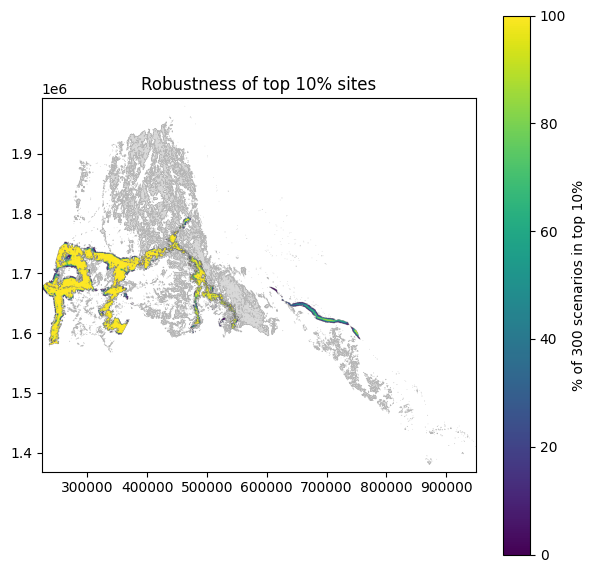

In [24]:
rng = np.random.default_rng(SEED)
N_SC = 300
mult = rng.uniform(0.7, 1.3, size=(N_SC, 5))
Wsc = W0 * mult
Wsc = Wsc / Wsc.sum(axis=1, keepdims=True)

base_top = score_v >= top_thr
count = np.zeros(S.shape[1], dtype="int32")
kept = np.zeros(N_SC)
for i, w in enumerate(Wsc):
    sc = w @ S
    top = sc >= np.percentile(sc, 90)
    count += top
    kept[i] = (top & base_top).sum() / base_top.sum()

freq = count / N_SC
robust = np.full((H, W), np.nan, dtype="float32")
robust[valid] = 100 * freq
save_tif(robust, f"{OUT}/robustness_top10_pct.tif")
df_w = pd.DataFrame(Wsc, columns=FACTORS)
df_w["kept_share"] = kept
df_w.to_csv(f"{OUT}/scenario_weights.csv", index=False)

print("Weight ranges actually tested:")
for j, f in enumerate(FACTORS):
    lo = round(Wsc[:, j].min(), 3)
    hi = round(Wsc[:, j].max(), 3)
    print("  ", f, lo, "to", hi, "(base", W0[j], ")")

print()
print("Baseline top 10% kept per scenario: mean",
      round(100 * kept.mean(), 1), "% | min",
      round(100 * kept.min(), 1), "%")
print("Area top 10% in ALL scenarios (km2):",
      round((freq == 1).sum() * 0.25))
print("Area top 10% in >=90% of scenarios (km2):",
      round((freq >= 0.9).sum() * 0.25))
print("Area top 10% in at least 1 scenario (km2):",
      round((freq > 0).sum() * 0.25))
print("Share of baseline top 10% that is robust (>=90%):",
      round(100 * (freq[base_top] >= 0.9).mean(), 1), "%")

print()
print("Correlation of each weight with 'kept':")
for j, f in enumerate(FACTORS):
    r = np.corrcoef(Wsc[:, j], kept)[0, 1]
    print("  ", f, "r =", round(r, 2))

plt.figure(figsize=(7, 7))
excl = np.where(MASK & ~valid, 1, np.nan)
plt.imshow(excl, cmap="Greys", vmin=0, vmax=4, extent=EXTENT)
show = np.where(robust > 0, robust, np.nan)
plt.imshow(show, cmap="viridis", vmin=0, vmax=100, extent=EXTENT)
plt.colorbar(label="% of 300 scenarios in top 10%")
plt.title("Robustness of top 10% sites")
plt.show()

Site cell usable: False
GHI 6.37 | slope 1.7 | land cover 50 | power km 0.0 | road km 0.0
Usable cells within 3 km: 84
Within 3 km  best score: 0.908 | best percentile: 98.0 | median score: 0.874 | max robustness: 100.0 %
GSA monthly GHI files found: 0
ERA5 grid point used: 15.0 39.0 | elevation 2007.0
ERA5 days: 7305 | missing: 0

GSA  GHI (kWh/m2/day): 6.37
ERA5 GHI (kWh/m2/day): 5.87
Bias ERA5 vs GSA: -7.9 %


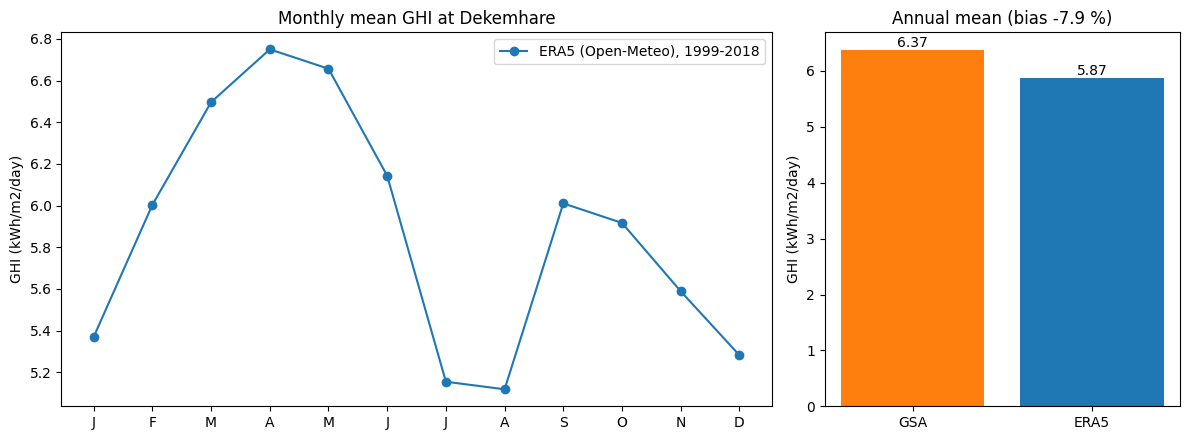

In [25]:
from rasterio.transform import rowcol
from pyproj import Transformer

SITE_LAT, SITE_LON = 15.07, 39.05   # Dekemhare town; replace if you find the plant

# --- Model values at the site ---
tr = Transformer.from_crs("EPSG:4326", CRS_WORK, always_xy=True)
sx, sy = tr.transform(SITE_LON, SITE_LAT)
r0, c0 = rowcol(TRANSFORM, sx, sy)
print("Site cell usable:", bool(valid[r0, c0]))
print("GHI", round(float(ghi[r0, c0]), 2), "| slope", round(float(slope[r0, c0]), 1),
      "| land cover", lc[r0, c0], "| power km", round(float(dpow[r0, c0]), 1),
      "| road km", round(float(droad[r0, c0]), 1))
if valid[r0, c0]:
    s0 = float(suit[r0, c0])
    print("Site score:", round(s0, 3),
          "| percentile:", round(100 * float((score_v < s0).mean()), 1),
          "| robustness:", round(float(robust[r0, c0]), 1), "%")

yy, xx = np.mgrid[0:H, 0:W]
near = (((yy - r0) ** 2 + (xx - c0) ** 2) <= (3000 / CELL) ** 2) & valid
print("Usable cells within 3 km:", int(near.sum()))
if near.sum():
    best = float(np.nanmax(suit[near]))
    print("Within 3 km  best score:", round(best, 3),
          "| best percentile:", round(100 * float((score_v < best).mean()), 1),
          "| median score:", round(float(np.nanmedian(suit[near])), 3),
          "| max robustness:", round(float(np.nanmax(robust[near])), 1), "%")

# --- Global Solar Atlas at the site (original ~250 m data) ---
zipf = glob.glob(f"{DATA}/*.zip")[0]
with zipfile.ZipFile(zipf) as z:
    names = z.namelist()
ghi_tifs = sorted(n for n in names
                  if "ghi" in n.lower() and n.lower().endswith(".tif"))
annual = [n for n in ghi_tifs if os.path.basename(n).lower() == "ghi.tif"][0]
months = [n for n in ghi_tifs if n != annual]
print("GSA monthly GHI files found:", len(months))

def gsa_at(name):
    with rasterio.open(f"/vsizip/{zipf}/{name}") as s:
        return float(list(s.sample([(SITE_LON, SITE_LAT)]))[0][0])

gsa_year = gsa_at(annual)
gsa_month = [gsa_at(n) for n in months] if len(months) == 12 else None

# --- ERA5 daily shortwave radiation (Open-Meteo archive) ---
p = dict(latitude=SITE_LAT, longitude=SITE_LON,
         start_date="1999-01-01", end_date="2018-12-31",
         daily="shortwave_radiation_sum", timezone="UTC", models="era5")
js = requests.get("https://archive-api.open-meteo.com/v1/archive",
                  params=p, timeout=180).json()
if "daily" not in js:
    raise RuntimeError(str(js))
print("ERA5 grid point used:", js["latitude"], js["longitude"],
      "| elevation", js.get("elevation"))
era = pd.DataFrame({"date": pd.to_datetime(js["daily"]["time"]),
                    "ghi": np.array(js["daily"]["shortwave_radiation_sum"],
                                    dtype=float) / 3.6})   # MJ -> kWh
era.to_csv(f"{OUT}/era5_dekemhare_daily.csv", index=False)
print("ERA5 days:", len(era), "| missing:", int(era.ghi.isna().sum()))

era_year = float(era.ghi.mean())
era_month = era.groupby(era.date.dt.month).ghi.mean()
bias = 100 * (era_year - gsa_year) / gsa_year
print()
print("GSA  GHI (kWh/m2/day):", round(gsa_year, 2))
print("ERA5 GHI (kWh/m2/day):", round(era_year, 2))
print("Bias ERA5 vs GSA:", round(bias, 1), "%")

# --- Figure ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5),
                       gridspec_kw={"width_ratios": [2, 1]})
m = np.arange(1, 13)
ax[0].plot(m, era_month.values, "o-", label="ERA5 (Open-Meteo), 1999-2018")
if gsa_month:
    ax[0].plot(m, gsa_month, "s-", label="Global Solar Atlas")
ax[0].set_xticks(m)
ax[0].set_xticklabels(list("JFMAMJJASOND"))
ax[0].set_ylabel("GHI (kWh/m2/day)")
ax[0].set_title("Monthly mean GHI at Dekemhare")
ax[0].legend()
ax[1].bar(["GSA", "ERA5"], [gsa_year, era_year], color=["tab:orange", "tab:blue"])
ax[1].set_title(f"Annual mean (bias {bias:+.1f} %)")
ax[1].set_ylabel("GHI (kWh/m2/day)")
for i, v in enumerate([gsa_year, era_year]):
    ax[1].text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.savefig(f"{OUT}/dekemhare_gsa_vs_era5.png", dpi=200)
plt.show()

In [26]:
for n in names: print(n)

Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/OPTA.tif.pdf
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/PVOUT.tif.pdf
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/DIF.tif.pdf
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/TEMP.tif.aux.xml
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/DNI.tif
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/GHI.tif.xml
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/OPTA.tif
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/GHI.tif.pdf
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/PVOUT.tif.aux.xml
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/DNI.tif.pdf
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/TEMP.tif
Eritrea_GISdata_LTAy_AvgDailyTotals_GlobalSolarAtlas-v2_GEOTIFF/PVOUT.tif.xml
Eritrea_GISdata_L

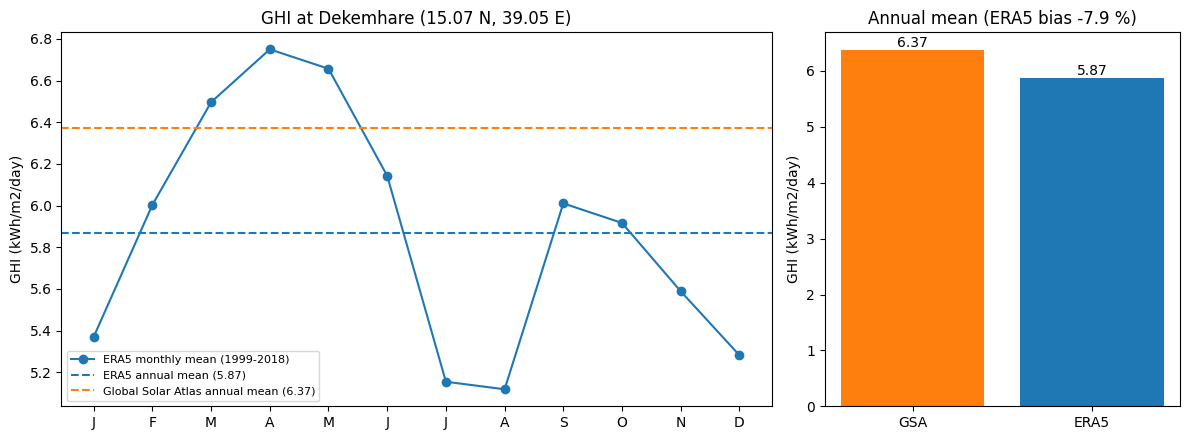

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5),
                       gridspec_kw={"width_ratios": [2, 1]})
m = np.arange(1, 13)
ax[0].plot(m, era_month.values, "o-", color="tab:blue",
           label="ERA5 monthly mean (1999-2018)")
ax[0].axhline(era_year, color="tab:blue", ls="--",
              label=f"ERA5 annual mean ({era_year:.2f})")
ax[0].axhline(gsa_year, color="tab:orange", ls="--",
              label=f"Global Solar Atlas annual mean ({gsa_year:.2f})")
ax[0].set_xticks(m)
ax[0].set_xticklabels(list("JFMAMJJASOND"))
ax[0].set_ylabel("GHI (kWh/m2/day)")
ax[0].set_title("GHI at Dekemhare (15.07 N, 39.05 E)")
ax[0].legend(fontsize=8, loc="lower left")

ax[1].bar(["GSA", "ERA5"], [gsa_year, era_year],
          color=["tab:orange", "tab:blue"])
ax[1].set_title(f"Annual mean (ERA5 bias {bias:+.1f} %)")
ax[1].set_ylabel("GHI (kWh/m2/day)")
for i, v in enumerate([gsa_year, era_year]):
    ax[1].text(i, v + 0.05, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.savefig(f"{OUT}/dekemhare_gsa_vs_era5.png", dpi=200)
plt.show()

In [29]:
def r(x, n=2):
    return round(float(x), n)

res = {}
n_all = MASK.sum()
res["area_km2"] = r(n_all * 0.25, 0)
res["excluded_slope_pct"] = r(100 * ex_slope.sum() / n_all, 1)
res["excluded_landcover_pct"] = r(100 * ex_lc.sum() / n_all, 1)
res["usable_km2"] = r(valid.sum() * 0.25, 0)
res["usable_pct"] = r(100 * valid.sum() / n_all, 1)
res["mean_factor_scores"] = {f: r(m) for f, m in zip(FACTORS, S.mean(axis=1))}
res["suit_min_median_max"] = [r(score_v.min(), 3), r(np.median(score_v), 3),
                              r(score_v.max(), 3)]
res["top10_threshold"] = r(top_thr, 3)
res["top10_km2"] = r((score_v >= top_thr).sum() * 0.25, 0)

res["scen_kept_mean_pct"] = r(100 * kept.mean(), 1)
res["scen_kept_min_pct"] = r(100 * kept.min(), 1)
res["top10_all300_km2"] = r((freq == 1).sum() * 0.25, 0)
res["top10_ge90pct_km2"] = r((freq >= 0.9).sum() * 0.25, 0)
res["top10_ever_km2"] = r((freq > 0).sum() * 0.25, 0)
res["baseline_top10_robust_pct"] = r(100 * (freq[base_top] >= 0.9).mean(), 1)
res["weight_vs_kept_r"] = {f: r(np.corrcoef(Wsc[:, j], kept)[0, 1])
                           for j, f in enumerate(FACTORS)}

res["power_gridfinder_km"] = r(grid.length.sum() / 1000, 0)
res["power_osm_km"] = r(power.length.sum() / 1000, 0)
res["roads_osm_km"] = r(roads.length.sum() / 1000, 0)
res["within50km_power_gridfinder_pct"] = r(100 * np.nanmean(d_power <= 50), 1)
res["within50km_power_osm_pct"] = r(100 * np.nanmean(d_power_osm <= 50), 1)

res["dek_cell_usable"] = bool(valid[r0, c0])
res["dek_cell_values"] = {"ghi": r(ghi[r0, c0]), "slope": r(slope[r0, c0], 1),
                          "landcover": int(lc[r0, c0]),
                          "power_km": r(dpow[r0, c0], 1),
                          "road_km": r(droad[r0, c0], 1)}
if valid[r0, c0]:
    s0 = suit[r0, c0]
    res["dek_score"] = r(s0, 3)
    res["dek_percentile"] = r(100 * (score_v < s0).mean(), 1)
    res["dek_robustness_pct"] = r(robust[r0, c0], 1)
if near.sum():
    b = np.nanmax(suit[near])
    res["dek3km_cells"] = int(near.sum())
    res["dek3km_best_score"] = r(b, 3)
    res["dek3km_best_percentile"] = r(100 * (score_v < b).mean(), 1)
    res["dek3km_median_score"] = r(np.nanmedian(suit[near]), 3)
    res["dek3km_max_robustness_pct"] = r(np.nanmax(robust[near]), 1)
res["gsa_ghi"] = r(gsa_year)
res["era5_ghi"] = r(era_year)
res["era5_bias_pct"] = r(bias, 1)

with open(f"{OUT}/results.json", "w") as f:
    json.dump(res, f, indent=1)
for k, v in res.items():
    print(k, ":", v)

area_km2 : 120382.0
excluded_slope_pct : 20.9
excluded_landcover_pct : 0.4
usable_km2 : 94684.0
usable_pct : 78.7
mean_factor_scores : {'GHI': 0.71, 'Slope': 0.74, 'Land cover': 0.92, 'Power lines': 0.43, 'Roads': 0.36}
suit_min_median_max : [0.184, 0.596, 0.961]
top10_threshold : 0.837
top10_km2 : 9468.0
scen_kept_mean_pct : 94.7
scen_kept_min_pct : 89.8
top10_all300_km2 : 6946.0
top10_ge90pct_km2 : 7942.0
top10_ever_km2 : 12508.0
baseline_top10_robust_pct : 83.9
weight_vs_kept_r : {'GHI': 0.1, 'Slope': -0.08, 'Land cover': -0.24, 'Power lines': 0.04, 'Roads': -0.0}
power_gridfinder_km : 1714.0
power_osm_km : 162.0
roads_osm_km : 3202.0
within50km_power_gridfinder_pct : 18.0
within50km_power_osm_pct : 3.5
dek_cell_usable : False
dek_cell_values : {'ghi': 6.37, 'slope': 1.7, 'landcover': 50, 'power_km': 0.0, 'road_km': 0.0}
dek3km_cells : 84
dek3km_best_score : 0.908
dek3km_best_percentile : 98.0
dek3km_median_score : 0.874
dek3km_max_robustness_pct : 100.0
gsa_ghi : 6.37
era5_ghi : 5.

In [30]:
res["slope_gt10_pct"] = r(100 * np.mean(slope[MASK] > 10), 1)
res["within50km_power_gridfinder_pct"] = r(100 * np.mean(d_power[MASK] <= 50), 1)
res["within50km_power_osm_pct"] = r(100 * np.mean(d_power_osm[MASK] <= 50), 1)
res["within20km_road_pct"] = r(100 * np.mean(d_roads[MASK] <= 20), 1)
with open(f"{OUT}/results.json", "w") as f:
    json.dump(res, f, indent=1)
for k in ["slope_gt10_pct", "within50km_power_gridfinder_pct",
          "within50km_power_osm_pct", "within20km_road_pct"]:
    print(k, ":", res[k])

slope_gt10_pct : 20.9
within50km_power_gridfinder_pct : 67.7
within50km_power_osm_pct : 13.3
within20km_road_pct : 56.4


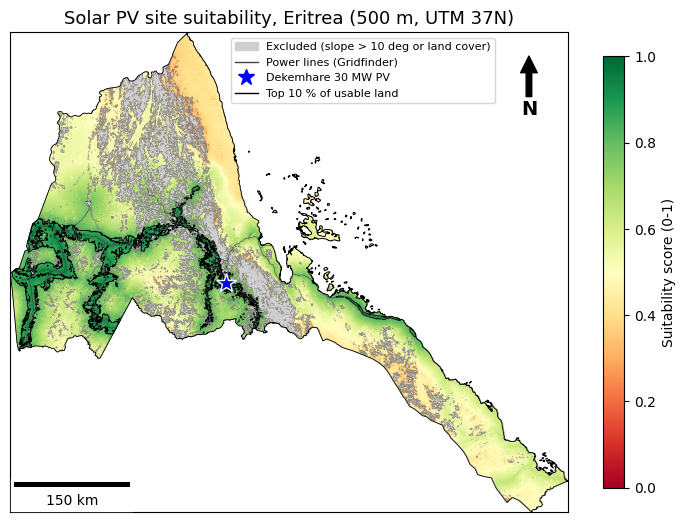

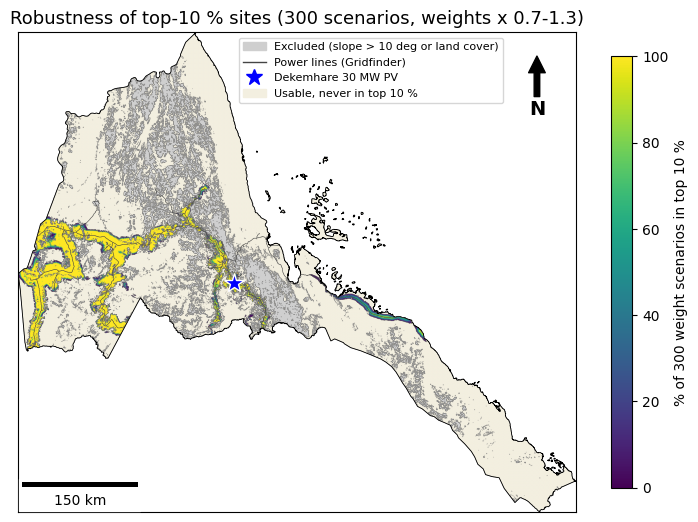

In [32]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

GREY = ListedColormap(["#cfcfcf"])
excl = np.where(MASK & ~valid, 1, np.nan)

def finish(ax, title):
    eri_utm.boundary.plot(ax=ax, color="black", linewidth=0.6)
    grid.plot(ax=ax, color="#444444", linewidth=0.4)
    ax.plot(sx, sy, marker="*", color="blue", markersize=15,
            markeredgecolor="white", linestyle="none")
    ax.add_artist(ScaleBar(1, "m", location="lower left",
                           length_fraction=0.25, box_alpha=0.8))
    ax.annotate("N", xy=(0.93, 0.95), xytext=(0.93, 0.84),
                xycoords="axes fraction", ha="center", va="center",
                fontsize=14, fontweight="bold",
                arrowprops=dict(facecolor="black", width=4, headwidth=12))
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title, fontsize=13)

common = [
    mpatches.Patch(color="#cfcfcf",
                   label="Excluded (slope > 10 deg or land cover)"),
    Line2D([], [], color="#444444", lw=1,
           label="Power lines (Gridfinder)"),
    Line2D([], [], marker="*", color="blue", ls="none", markersize=12,
           label="Dekemhare 30 MW PV"),
]

# Map 1: suitability
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(excl, cmap=GREY, extent=EXTENT)
im = ax.imshow(suit, cmap="RdYlGn", vmin=0, vmax=1, extent=EXTENT)
ax.contour(np.where(valid, suit >= top_thr, 0), levels=[0.5],
           colors="black", linewidths=0.6, extent=EXTENT, origin="upper")
plt.colorbar(im, ax=ax, shrink=0.7, label="Suitability score (0-1)")
handles = common + [Line2D([], [], color="black", lw=1,
                           label="Top 10 % of usable land")]
ax.legend(handles=handles, loc="upper right",
          bbox_to_anchor=(0.88, 1), fontsize=8)
finish(ax, "Solar PV site suitability, Eritrea (500 m, UTM 37N)")
plt.savefig(f"{OUT}/map_suitability.png", dpi=200, bbox_inches="tight")
plt.show()

# Map 2: robustness
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(excl, cmap=GREY, extent=EXTENT)
never = np.where(valid & (robust == 0), 1, np.nan)
ax.imshow(never, cmap=ListedColormap(["#f3efe0"]), extent=EXTENT)
im = ax.imshow(np.where(robust > 0, robust, np.nan), cmap="viridis",
               vmin=0, vmax=100, extent=EXTENT)
plt.colorbar(im, ax=ax, shrink=0.7,
             label="% of 300 weight scenarios in top 10 %")
handles = common + [mpatches.Patch(color="#f3efe0",
                                   label="Usable, never in top 10 %")]
ax.legend(handles=handles, loc="upper right",
          bbox_to_anchor=(0.88, 1), fontsize=8)
finish(ax, "Robustness of top-10 % sites (300 scenarios, weights x 0.7-1.3)")
plt.savefig(f"{OUT}/map_robustness.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:
print("slope_gt10_pct :", round(100 * np.mean(slope[MASK] > 10), 1))
print("power_gridfinder_50km_pct :", round(100 * np.mean(d_power[MASK] <= 50), 1))
print("power_osm_50km_pct :", round(100 * np.mean(d_power_osm[MASK] <= 50), 1))
print("road_20km_pct :", round(100 * np.mean(d_roads[MASK] <= 20), 1))

slope_gt10_pct : 20.9
power_gridfinder_50km_pct : 67.7
power_osm_50km_pct : 13.3
road_20km_pct : 56.4
